# Прогнозирование продаж товара 85099B (JUMBO BAG RED RETROSPOT)

Это продолжение первого домашнего задания. Там мы разобрали ряд продаж товара 85099B из датасета Online Retail, а здесь строим по нему прогнозы на дневной, недельной и месячной частоте и сравниваем несколько моделей на разных горизонтах.

Все функции лежат в файле [forecasting.py](forecasting.py), в ноутбуке только их вызовы и комментарии к результатам.

In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import forecasting as fc

warnings.filterwarnings("ignore")   # statsmodels часто предупреждает о сходимости на коротких рядах
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12})

STOCK_CODE = "85099B"

## 1. Подготовка данных

Ряды строятся по тем же правилам, что и в первом задании. Продажи считаем в штуках, отмены и строки с нулевой ценой или количеством не учитываем. В дневном ряду оставляем только дни, когда магазин работал: суббот, Рождества и праздников в нём нет. Из недельного и месячного рядов убраны неполные периоды на краях и неделя, когда магазин был закрыт целиком.

In [2]:
df = fc.load_online_retail("data")   # если файла нет, скачается с UCI
series = fc.build_series(df, STOCK_CODE)
fc.check_series(series)

,наблюдений,начало,конец,даты по возрастанию,даты уникальны,пропусков (NaN),типичный шаг,макс. шаг
D,305,2010-12-01,2011-12-09,True,True,0,1 days 00:00:00,12 days 00:00:00
W,51,2010-12-12,2011-12-04,True,True,0,7 days 00:00:00,14 days 00:00:00
M,12,2010-12-01,2011-11-01,True,True,0,31 days 00:00:00,31 days 00:00:00


Даты во всех рядах идут по возрастанию, повторов и пропусков нет. Обычно дни в дневном ряду идут подряд, но иногда между соседними наблюдениями больше: это выходные и праздники, когда магазин не работал. Самый большой разрыв, 12 дней, приходится на Рождество. Поэтому один шаг дневного ряда равен одному рабочему дню магазина, и горизонт 61 шаг примерно соответствует двум с половиной месяцам. В недельном ряду один шаг в 14 дней на месте рождественской недели, в месячном все шаги регулярные.

Получилось 305 дневных, 51 недельное и 12 месячных наблюдений.

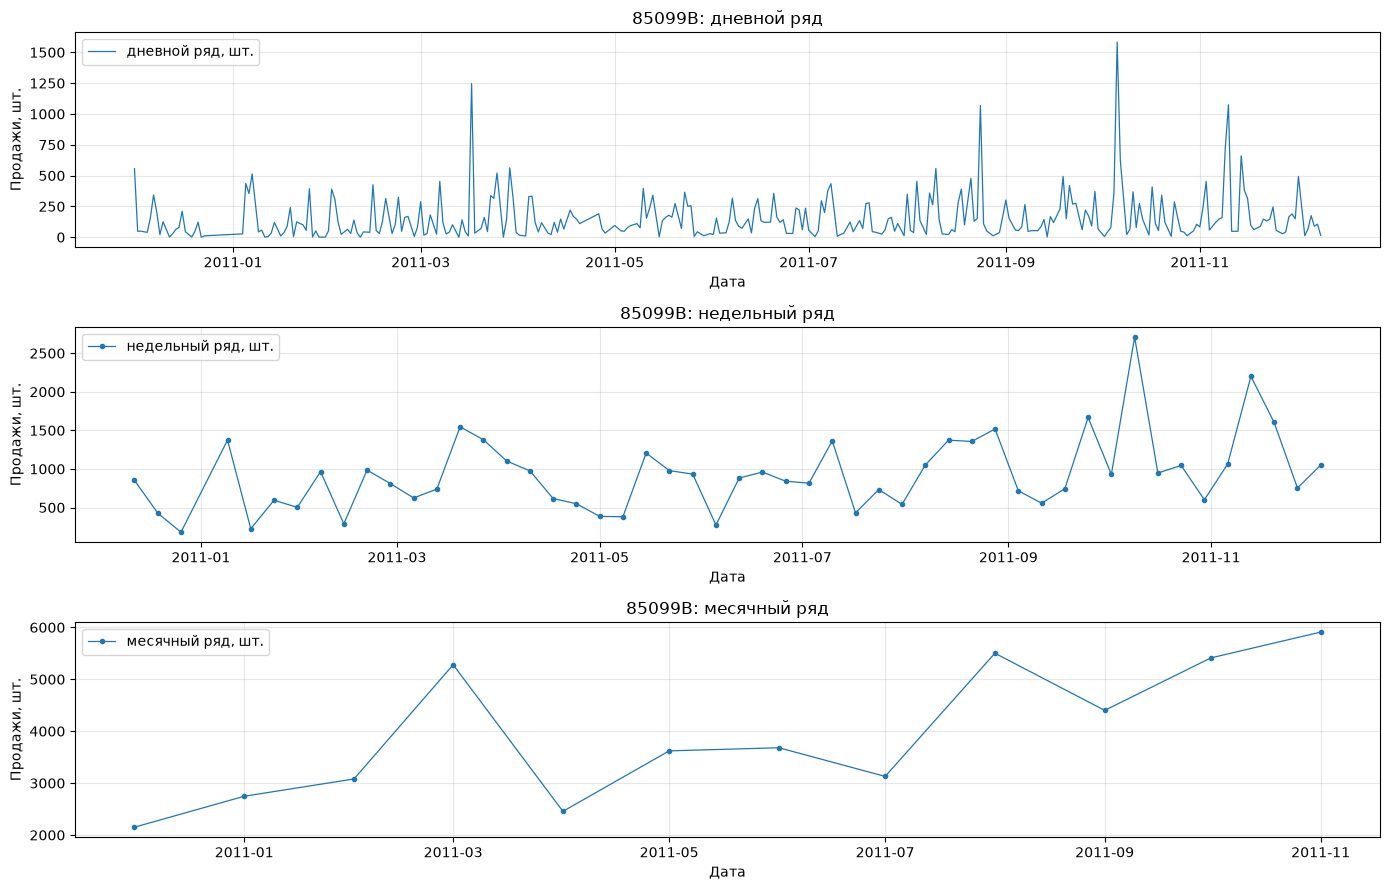

In [3]:
fc.plot_series(series, STOCK_CODE)

## 2. Как устроен эксперимент

Если просто отрезать от ряда последние точки и один раз сравнить с ними прогноз, результат будет сильно зависеть от того, какие именно недели попали в тест. Особенно это заметно на месячном ряду: для горизонта 1 метрика считалась бы по одному числу. Поэтому используем проверку со скользящим началом прогноза (rolling origin).

Выбираем несколько точек старта в конце ряда. В каждой точке модель обучается только на данных до неё и строит прогноз на максимальный горизонт для своей частоты. Потом точка старта сдвигается вперёд, модель переобучается на удлинённой истории, и всё повторяется. Так будущие наблюдения никогда не попадают в обучение, а для каждого горизонта набирается несколько проверок.

Качество на горизонте h считаем по шагам с 1 по h каждого прогноза, то есть так, как если бы нужен был прогноз на h шагов вперёд. Для всех горизонтов одной частоты используются одни и те же точки старта и одни и те же прогнозы, поэтому модели сравниваются в одинаковых условиях.

По частотам это выглядит так:
- дневной ряд: горизонты 1, 7, 31 и 61 рабочий день, 20 точек старта через каждые 3 дня, обучающая часть от 187 до 244 дней;
- недельный ряд: горизонты 1, 4 и 8 недель, 8 точек старта подряд, обучение от 36 до 43 недель;
- месячный ряд: горизонты 1 и 2 месяца, 3 точки старта, обучение от 8 до 10 месяцев.

Месячных данных совсем мало, поэтому выводы по ним самые ненадёжные: всего 3 прогноза на горизонт 1 и 6 точек на горизонт 2.

## 3. Модели

Сравниваем три модели, а для ориентира добавляем наивный прогноз. Для дневного ряда это сезонный наивный прогноз: следующая неделя повторяет последнюю (6 рабочих дней), потому что в первом задании нашлась недельная сезонность. Для недель и месяцев прогноз просто равен последнему значению.

ETS, то есть экспоненциальное сглаживание Холта–Уинтерса, берём с затухающим трендом, а для дневного ряда добавляем сезонность с периодом 6. Затухающий тренд выбран, чтобы прогноз на длинный горизонт не улетал вверх по прямой.

SARIMA строим с линейным трендом: в первом задании ряд оказался стационарным вокруг тренда, поэтому тренд включён в модель напрямую, а не через разности. Порядки выбраны по автокорреляциям из первого задания: для дней SARIMA(1,0,1)(1,0,1) с периодом 6, для недель AR(1). Для месяцев при 8–10 точках обучения больше двух-трёх параметров не оценить, поэтому там остаётся только линейный тренд (ARIMA(0,0,0) с трендом).

Градиентный бустинг (GradientBoostingRegressor из scikit-learn) обучается на лаговых признаках: значениях ряда несколько шагов назад, среднем за последние шаги и, для дневного ряда, номере дня в неделе. Деревья не умеют продолжать тренд за пределы значений, которые видели при обучении, поэтому линейный тренд сначала вычитается, бустинг учится на остатках, а тренд потом добавляется обратно. Прогноз на несколько шагов строится рекурсивно: каждый спрогнозированный шаг становится лагом для следующего.

Все модели, кроме наивной, обучаются на логарифме продаж. В первом задании разброс рос вместе с уровнем (корреляция среднего и std по кварталам около 0.84), а после логарифма одинаковый рост в процентах становится одинаковым по величине, и колебания выравниваются. Логарифм ещё и ослабляет оптовые всплески: модели при обучении минимизируют квадраты ошибок, и день на 1500 штук при обычных 100 перетягивал бы на себя оценку параметров. В логарифмах такой всплеск больше обычного дня примерно в 1.6 раза, а не в 15. Наконец, в первом задании ряд стал стационарным как раз после логарифма и вычитания тренда.

Берём log(1 + y), а не обычный логарифм, потому что в дневном ряду есть дни с нулевыми продажами, а log(0) не определён. На сотнях и тысячах штук прибавка единицы почти ничего не меняет. Прогноз потом переводится обратно в штуки через exp(x) − 1.

Стоит учитывать, что прогноз на логарифмах ближе к типичному значению (медиане), чем к среднему, поэтому суммарные продажи он может немного занижать.

In [4]:
EXPERIMENTS = {
    "D": dict(horizons=[1, 7, 31, 61], n_origins=20, step=3, mase_season=6, models={
        "Naive": lambda train, h: np.resize(train.values[-6:], h),   # повтор последней недели
        "ETS": lambda train, h: fc.forecast_ets(train, h, season=6),
        "SARIMA": lambda train, h: fc.forecast_sarima(train, h, order=(1, 0, 1), seasonal_order=(1, 0, 1, 6)),
        "Boosting": lambda train, h: fc.forecast_boosting(train, h, lags=(1, 2, 3, 6, 12), season=6),
    }),
    "W": dict(horizons=[1, 4, 8], n_origins=8, step=1, mase_season=1, models={
        "Naive": lambda train, h: np.repeat(train.values[-1], h),   # последнее значение
        "ETS": lambda train, h: fc.forecast_ets(train, h),
        "SARIMA": lambda train, h: fc.forecast_sarima(train, h, order=(1, 0, 0)),
        "Boosting": lambda train, h: fc.forecast_boosting(train, h, lags=(1, 2, 4)),
    }),
    "M": dict(horizons=[1, 2], n_origins=3, step=1, mase_season=1, models={
        "Naive": lambda train, h: np.repeat(train.values[-1], h),   # последнее значение
        "ETS": lambda train, h: fc.forecast_ets(train, h),
        "SARIMA": lambda train, h: fc.forecast_sarima(train, h, order=(0, 0, 0)),
        "Boosting": lambda train, h: fc.forecast_boosting(train, h, lags=(1, 2), min_samples_leaf=1),
    }),
}

## 4. Метрики

Для оценки берём MAE, RMSE, WAPE и MASE.

MAE показывает среднюю абсолютную ошибку в штуках. Её проще всего объяснить: на сколько штук в среднем ошибается прогноз.

RMSE тоже измеряется в штуках, но сильнее штрафует большие промахи. Для этого товара это важно, потому что продажи иногда резко подскакивают из-за крупных оптовых заказов. Если RMSE заметно больше MAE, значит, основная часть ошибки приходится на редкие большие промахи.

WAPE считается как сумма абсолютных ошибок, делённая на сумму фактических продаж, и выражается в процентах. MAE и RMSE зависят от масштаба: недельные продажи в несколько раз больше дневных, а месячные ещё больше, поэтому сравнивать частоты по ним нельзя. WAPE от масштаба не зависит. Привычный MAPE здесь не подходит: в дневном ряду есть дни с нулевыми продажами, и на них MAPE делится на ноль. Поэтому модели в основном сравниваем по WAPE.

MASE равна MAE модели, делённой на MAE наивного прогноза внутри обучающей части. Значение меньше 1 означает, что модель ошибается меньше, чем наивный прогноз ошибался на истории.

## 5. Прогнозы и метрики по частотам
### Дневной ряд

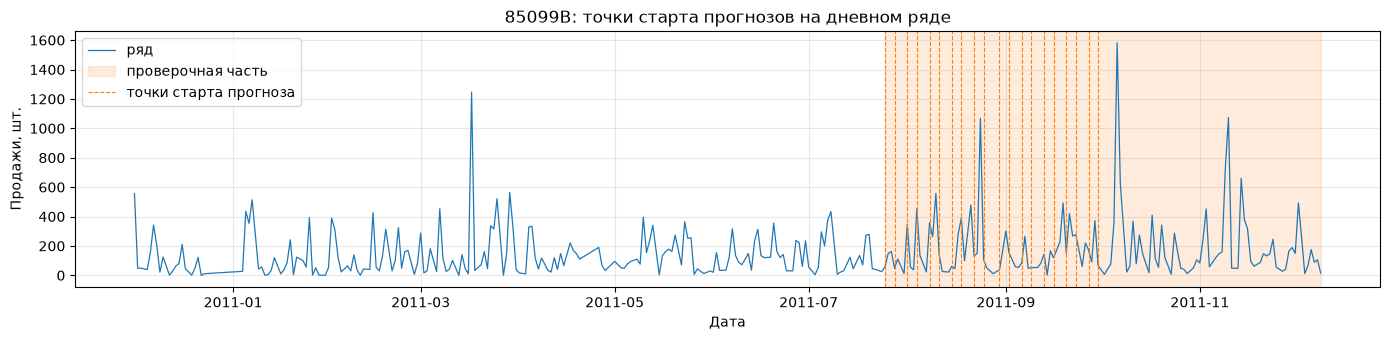

,horizon,model,n_forecasts,MAE,RMSE,"WAPE, %",MASE,freq
0,1,Naive,20,136.00,183.33,80.95,0.96,D
1,1,ETS,20,96.99,141.16,57.73,0.69,D
2,1,SARIMA,20,94.49,131.76,56.24,0.67,D
3,1,Boosting,20,96.17,131.51,57.25,0.68,D
4,7,Naive,140,179.05,260.74,94.28,1.26,D
5,7,ETS,140,131.78,233.14,69.38,0.93,D
6,7,SARIMA,140,131.64,222.34,69.31,0.92,D
7,7,Boosting,140,130.41,219.85,68.67,0.92,D
8,31,Naive,620,183.61,293.51,91.96,1.29,D
9,31,ETS,620,144.51,267.43,72.38,1.01,D


In [5]:
forecasts, metrics = {}, {}
for freq, cfg in EXPERIMENTS.items():
    forecasts[freq] = fc.backtest(series[freq], cfg["models"], cfg["horizons"],
                                  cfg["n_origins"], cfg["step"], cfg["mase_season"])
    metrics[freq] = fc.evaluate(forecasts[freq], cfg["horizons"]).assign(freq=freq)

fc.plot_split(series["D"], forecasts["D"], f"{STOCK_CODE}: точки старта прогнозов на дневном ряде")
metrics["D"]

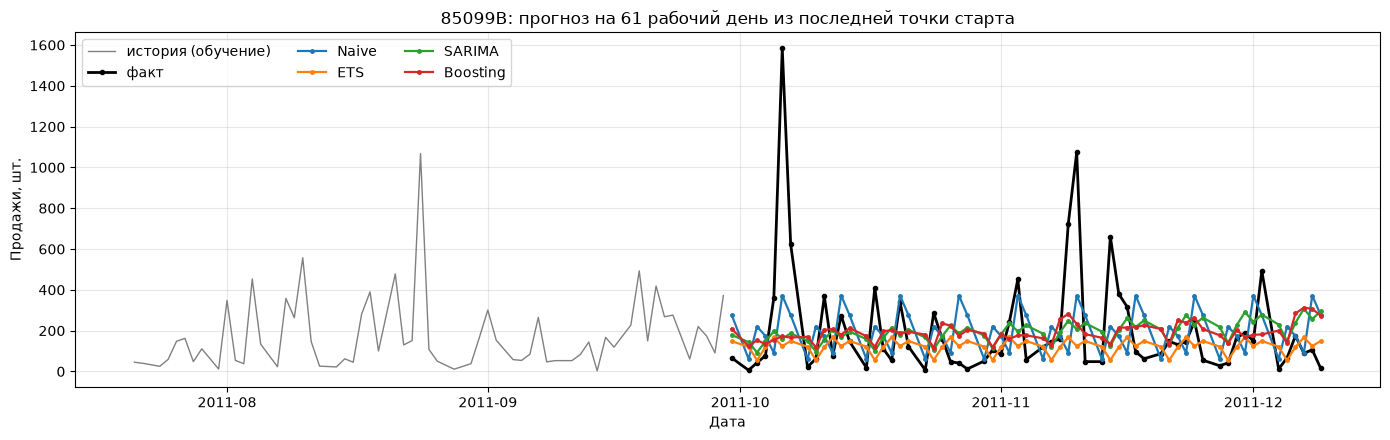

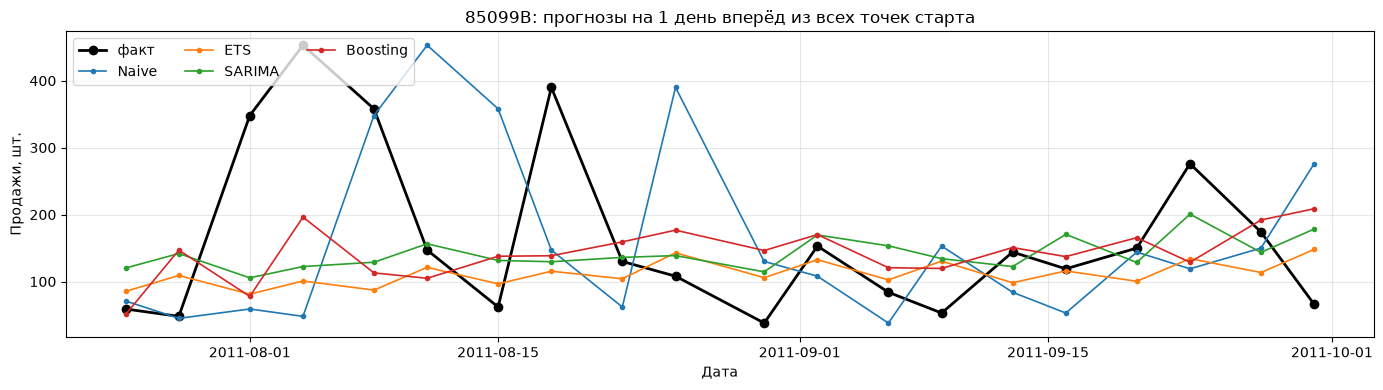

In [6]:
fc.plot_last_forecast(series["D"], forecasts["D"],
                      f"{STOCK_CODE}: прогноз на 61 рабочий день из последней точки старта", history=60)
fc.plot_one_step(forecasts["D"], f"{STOCK_CODE}: прогнозы на 1 день вперёд из всех точек старта")

На дневном ряде все три модели заметно лучше наивного прогноза: WAPE около 56–58 % на горизонте 1 против 81 % у наивного. При этом сами модели почти не отличаются друг от друга, разница между ними 1–3 процентных пункта. На 20 точках старта это скорее случайность, чем реальное превосходство одной из них.

Ошибка всё равно большая, и причина видна на графиках. Модели прогнозируют гладкий средний уровень с небольшими колебаниями по дням недели, а реальные продажи скачут в разы из-за крупных заказов, которые заранее не предсказать. Поэтому RMSE в 1.4–1.8 раза больше MAE: значительную часть ошибки дают редкие сильные пики.

### Недельный ряд

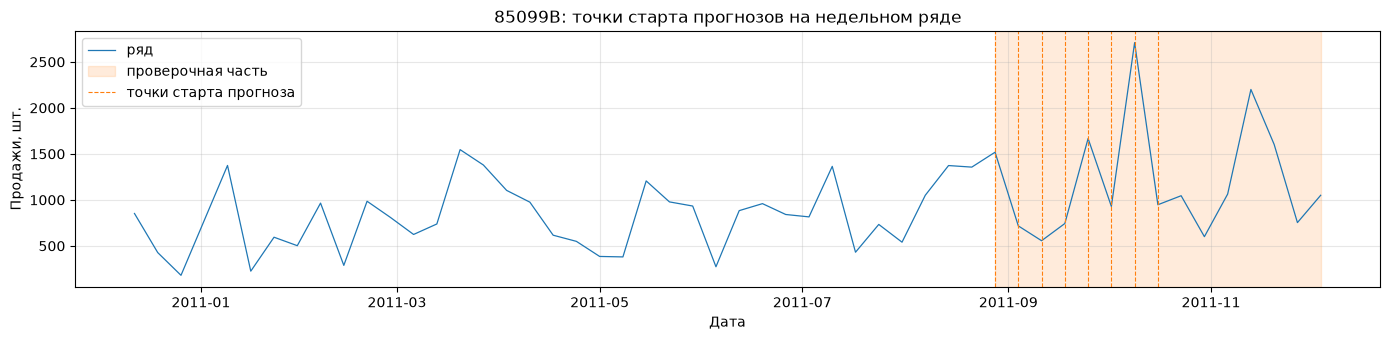

,horizon,model,n_forecasts,MAE,RMSE,"WAPE, %",MASE,freq
0,1,Naive,8,814.38,1024.71,66.57,2.07,W
1,1,ETS,8,524.66,755.04,42.89,1.36,W
2,1,SARIMA,8,519.49,709.98,42.47,1.35,W
3,1,Boosting,8,648.76,798.85,53.04,1.69,W
4,4,Naive,32,809.38,1035.47,68.16,2.07,W
5,4,ETS,32,469.07,733.81,39.50,1.23,W
6,4,SARIMA,32,470.81,690.81,39.65,1.23,W
7,4,Boosting,32,671.54,820.60,56.55,1.74,W
8,8,Naive,64,739.03,952.00,58.80,1.89,W
9,8,ETS,64,491.23,742.24,39.09,1.28,W


In [7]:
fc.plot_split(series["W"], forecasts["W"], f"{STOCK_CODE}: точки старта прогнозов на недельном ряде")
metrics["W"]

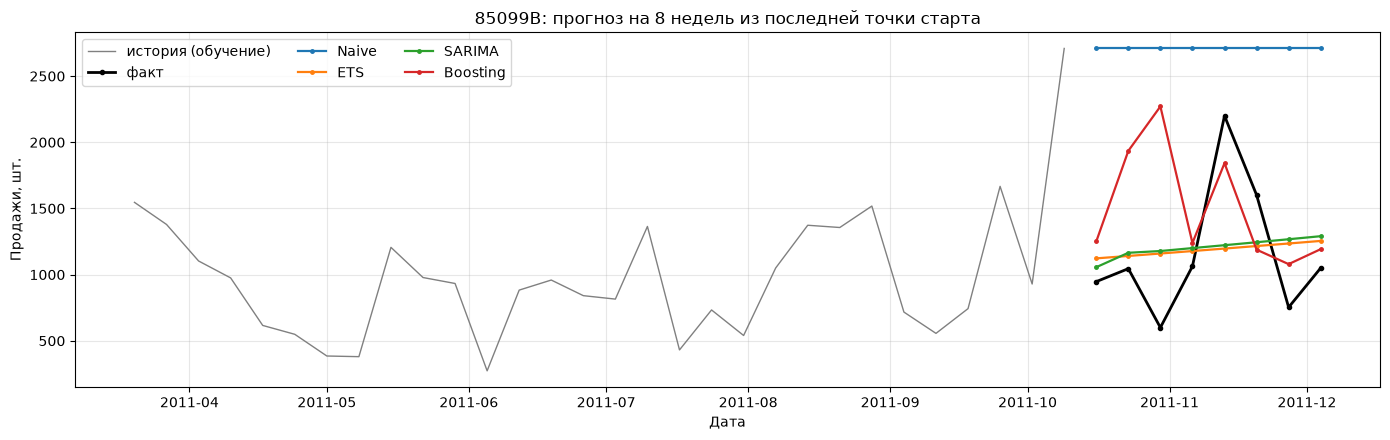

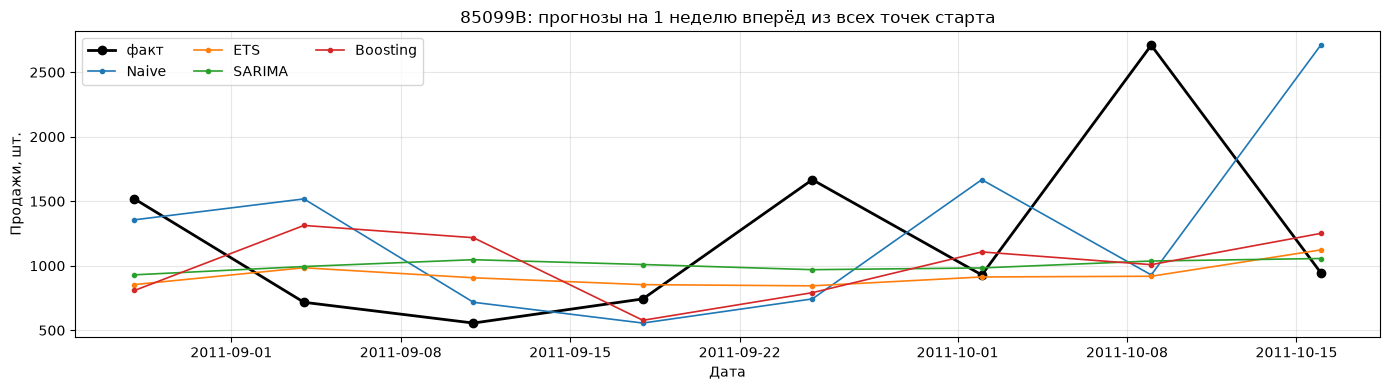

In [8]:
fc.plot_last_forecast(series["W"], forecasts["W"],
                      f"{STOCK_CODE}: прогноз на 8 недель из последней точки старта", history=30)
fc.plot_one_step(forecasts["W"], f"{STOCK_CODE}: прогнозы на 1 неделю вперёд из всех точек старта")

На неделях лучше всего работают ETS и SARIMA: WAPE около 38–43 %, они почти одинаковые. Бустинг заметно отстаёт (49–57 %), хотя и обгоняет наивный прогноз. Для обучения у него всего 32–39 строк, на таком объёме деревьям трудно найти устойчивые закономерности, а статистические модели с парой параметров чувствуют себя лучше. Кроме того, на графике последнего прогноза видно, что перед точкой старта был всплеск продаж (около 2700 штук), он попал в лаги, и бустинг перенёс его в прогноз на следующие недели. ETS и SARIMA сглаживают такой выброс гораздо сильнее.

При этом MASE у всех моделей больше 1, хотя по WAPE они сильно лучше наивного прогноза. Так получается потому, что MASE сравнивает ошибку с ошибкой наивного прогноза на обучающей части, а осенью 2011 продажи и их разброс выросли. На более спокойной истории наивный прогноз ошибался меньше, поэтому знаменатель получается маленьким. Сравнивать модели между собой правильнее по WAPE на одном и том же тестовом периоде.

### Месячный ряд

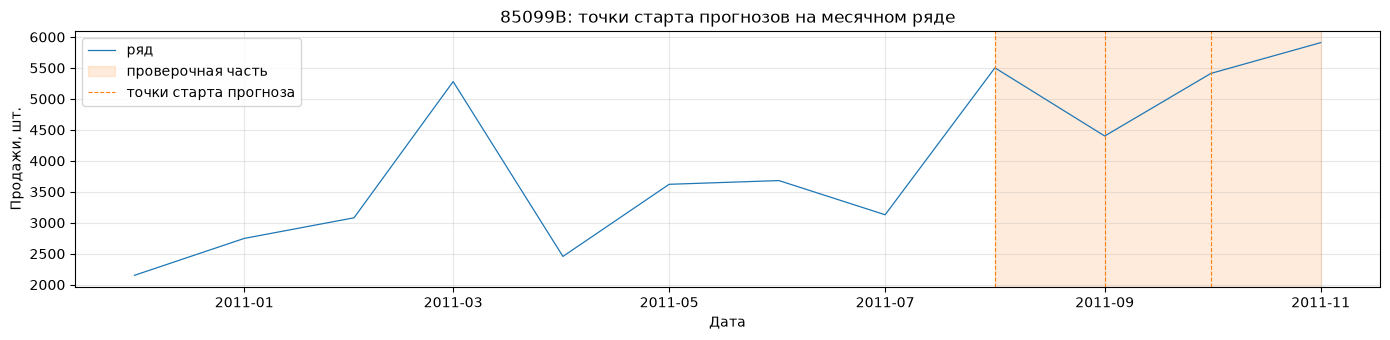

,horizon,model,n_forecasts,MAE,RMSE,"WAPE, %",MASE,freq
0,1,Naive,3,1495.00,1619.20,29.29,1.28,M
1,1,ETS,3,979.33,1176.60,19.18,0.85,M
2,1,SARIMA,3,839.95,1041.14,16.45,0.73,M
3,1,Boosting,3,1503.63,1630.19,29.45,1.25,M
4,2,Naive,6,1225.83,1400.33,23.70,1.04,M
5,2,ETS,6,1012.62,1143.14,19.58,0.85,M
6,2,SARIMA,6,662.83,817.62,12.81,0.57,M
7,2,Boosting,6,1095.76,1351.40,21.18,0.91,M


In [9]:
fc.plot_split(series["M"], forecasts["M"], f"{STOCK_CODE}: точки старта прогнозов на месячном ряде")
metrics["M"]

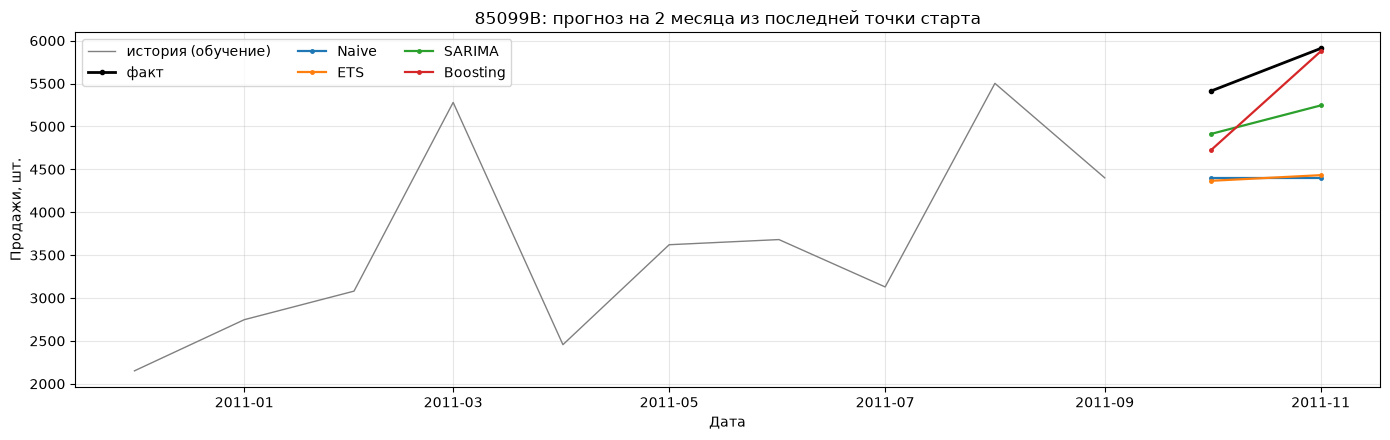

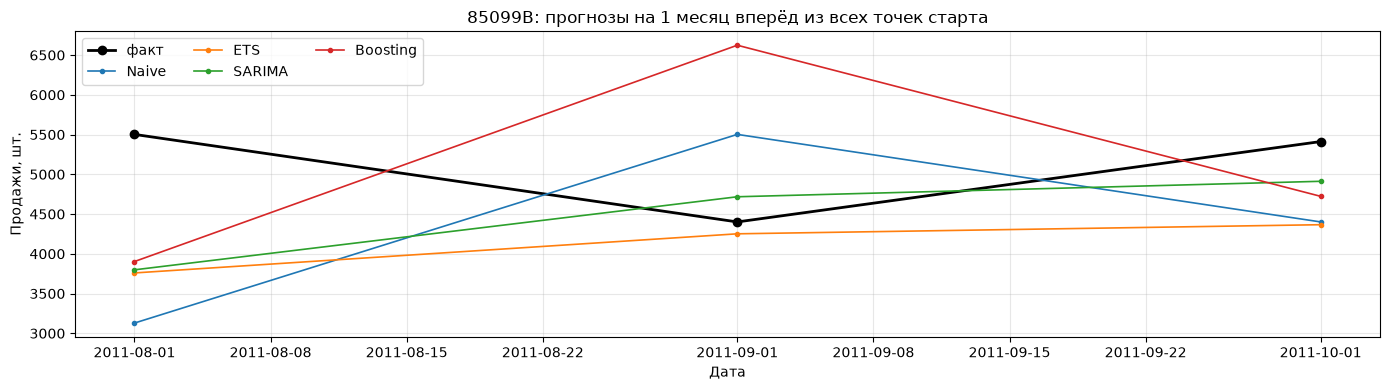

In [10]:
fc.plot_last_forecast(series["M"], forecasts["M"],
                      f"{STOCK_CODE}: прогноз на 2 месяца из последней точки старта", history=12)
fc.plot_one_step(forecasts["M"], f"{STOCK_CODE}: прогнозы на 1 месяц вперёд из всех точек старта")

На месячном ряде лучше всех оказался самый простой вариант: SARIMA, которая при 8–10 точках сводится к линейному тренду. WAPE у неё 16 % на горизонте 1 и 13 % на горизонте 2. Продажи в течение года почти всё время росли, и прямая линия это хорошо ловит. ETS немного хуже из-за затухающего тренда, а бустинг на горизонте 1 не лучше наивного прогноза: учиться ему не на чем.

Делать по этим числам сильные выводы нельзя: на горизонт 1 всего 3 прогноза, а на горизонт 2 шесть точек.

## 6. Сводное сравнение

In [11]:
summary = pd.concat(metrics.values(), ignore_index=True)
summary = summary[["freq", "horizon", "model", "n_forecasts", "MAE", "RMSE", "WAPE, %", "MASE"]]
summary

,freq,horizon,model,n_forecasts,MAE,RMSE,"WAPE, %",MASE
0,D,1,Naive,20,136.00,183.33,80.95,0.96
1,D,1,ETS,20,96.99,141.16,57.73,0.69
2,D,1,SARIMA,20,94.49,131.76,56.24,0.67
3,D,1,Boosting,20,96.17,131.51,57.25,0.68
4,D,7,Naive,140,179.05,260.74,94.28,1.26
5,D,7,ETS,140,131.78,233.14,69.38,0.93
6,D,7,SARIMA,140,131.64,222.34,69.31,0.92
7,D,7,Boosting,140,130.41,219.85,68.67,0.92
8,D,31,Naive,620,183.61,293.51,91.96,1.29
9,D,31,ETS,620,144.51,267.43,72.38,1.01


Та же таблица, развёрнутая по WAPE, удобнее для сравнения. В строках частота и горизонт, в столбцах модели.

In [12]:
summary.pivot_table(index=["freq", "horizon"], columns="model", values="WAPE, %", sort=False)[
    ["Naive", "ETS", "SARIMA", "Boosting"]]

model         Naive    ETS  SARIMA  Boosting
freq horizon                                
D    1        80.95  57.73   56.24     57.25
     7        94.28  69.38   69.31     68.67
     31       91.96  72.38   72.59     74.35
     61       88.13  74.45   77.78     77.69
W    1        66.57  42.89   42.47     53.04
     4        68.16  39.50   39.65     56.55
     8        58.80  39.09   37.83     49.26
M    1        29.29  19.18   16.45     29.45
     2        23.70  19.58   12.81     21.18

In [13]:
fc.best_models(summary)

,freq,horizon,model,MAE,"WAPE, %",MASE
0,D,1,SARIMA,94.49,56.24,0.67
1,D,7,Boosting,130.41,68.67,0.92
2,D,31,ETS,144.51,72.38,1.01
3,D,61,ETS,154.27,74.45,1.08
4,W,1,SARIMA,519.49,42.47,1.35
5,W,4,ETS,469.07,39.50,1.23
6,W,8,SARIMA,475.39,37.83,1.24
7,M,1,SARIMA,839.95,16.45,0.73
8,M,2,SARIMA,662.83,12.81,0.57


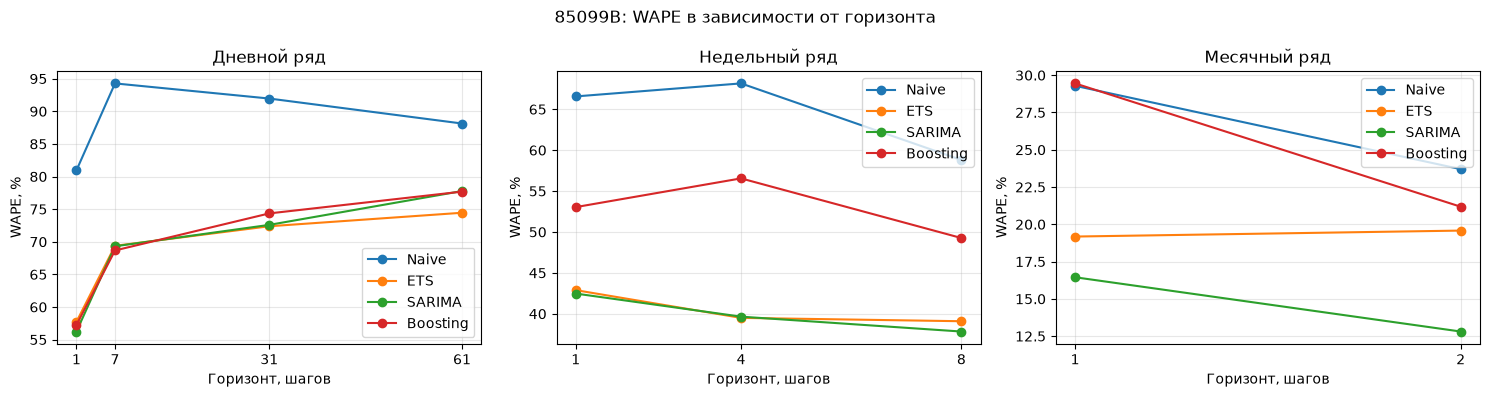

In [14]:
fc.plot_metric_by_horizon(summary, 'WAPE, %', f'{STOCK_CODE}: WAPE в зависимости от горизонта')

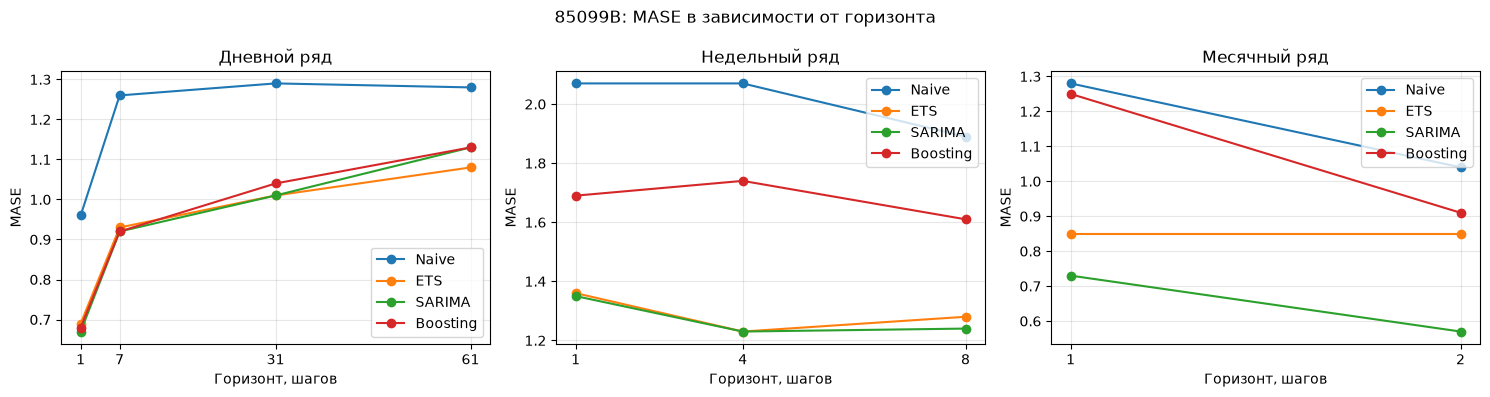

In [15]:
fc.plot_metric_by_horizon(summary, 'MASE', f'{STOCK_CODE}: MASE в зависимости от горизонта')

На дневном ряде качество с ростом горизонта ухудшается, как и ожидалось: WAPE лучших моделей растёт примерно с 56 % на 1 день до 74–78 % на 61 день. Чем дальше прогноз, тем сильнее модели расходятся с реальностью в уровне, а сезонный профиль и последние значения перестают помогать. На длинных горизонтах чуть лучше остальных ETS: затухающий тренд не уводит прогноз слишком далеко.

На неделях и месяцах такой картины нет: на длинном горизонте ошибка не больше, чем на коротком. Прогноз этих моделей по сути состоит из уровня и тренда, и ошибка определяется в основном шумом конкретных недель, а не тем, насколько далеко мы заглядываем. К тому же точек для проверки мало, и одна неудачная неделя заметно сдвигает метрику.

Между частотами WAPE сильно отличается: около 56–78 % для дней, 38–57 % для недель и 13–29 % для месяцев. Чем крупнее агрегация, тем больше случайных скачков взаимно гасится, и тем точнее прогноз в процентах.

## 7. Выводы

1. Построены и сравнены три модели (ETS, SARIMA и градиентный бустинг на лагах) и наивная базовая линия на дневном, недельном и месячном рядах. Проверка шла со скользящим началом прогноза, поэтому модели обучались только на прошлых данных, а для каждого горизонта было несколько проверок.
2. На дневном ряде все три модели примерно одинаковы и заметно лучше наивного прогноза. На горизонтах 1, 7 и 31 разница между ними в пределах 1–2 процентных пунктов, на 61 день ETS лучше остальных примерно на 3 пункта.
3. На недельном ряде лучше всего ETS и SARIMA (WAPE около 38–43 %), бустинг заметно хуже из-за маленькой обучающей выборки.
4. На месячном ряде лучший результат у самой простой модели, линейного тренда (WAPE 13–16 %). Бустинг на 8–10 точках не лучше наивного прогноза. Выводы по месяцам ненадёжны из-за очень малого числа проверок.
5. На дневном ряде качество с ростом горизонта ухудшается: WAPE растёт с 56 % на 1 день до 74–78 % на 61 день. На неделях и месяцах ошибка от горизонта почти не зависит, её определяет шум отдельных периодов.
6. Больше всего ошибок дают крупные оптовые заказы, которые резко поднимают продажи в отдельные дни и недели. Ни одна модель не может их предсказать по прошлым продажам, поэтому дневной прогноз остаётся неточным. Кроме того, история короткая. Данных всего за год, годовую сезонность модели не видят, а бустингу на недельных и месячных данных просто не хватает примеров для обучения.